# 📈 Le grandi Borse del mondo: 9 indici a confronto

Progetto di **Francesco Autorino** – Data Analyst.

❓ **La domanda**: come si sono comportati i principali indici di Borsa del mondo negli ultimi 20 anni?

Le 5 domande più piccole:

1️⃣ 🏆 Quale indice è cresciuto di più dal 2007 a oggi?

2️⃣ 💶 Cambia qualcosa se conto tutto in euro?

3️⃣ 🎢 Quale indice è più rischioso (sale e scende di più)?

4️⃣ 📉 Quanto hanno perso nelle crisi e quanto ci hanno messo a recuperare?

5️⃣ 🔗 Le Borse si muovono insieme?

📊 Dati: chiusure giornaliere di 9 indici dal 2000 al 26 ottobre 2026 (Yahoo Finance) e i cambi dell'euro.

⚠️ **Solo analisi storica**: i risultati del passato non dicono nulla sul futuro. Non è un consiglio di investimento.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

DATI = Path("../02Dati/2Puliti")
GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
indici = pd.read_csv(DATI / "indici.csv")
prezzi = pd.read_csv(DATI / "prezzi_giornalieri.csv.gz", parse_dates=["data"])
cambi = pd.read_csv(DATI / "cambi.csv", parse_dates=["data"])
annui = pd.read_csv(DATI / "rendimenti_annui.csv")
riep = pd.read_csv(DATI / "riepilogo_indici.csv").merge(indici, on="codice")
crisi = pd.read_csv(DATI / "crisi.csv").merge(indici[["codice", "nome"]], on="codice")
corr = pd.read_csv(DATI / "correlazioni.csv")

NOME = dict(zip(indici.codice, indici.nome)); COLORE = dict(zip(indici.codice, indici.colore))
ORDINE = indici.sort_values("ordine").codice.tolist()
# colori del progetto: verde bosco, oro, avorio, rosso
BOSCO, ORO, AVORIO, ROSSO, GRAFITE = "#0F3D2E", "#C9A227", "#FBF8F0", "#B03A2E", "#2B2B2B"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", bbox_inches="tight"); plt.show()

pct = lambda v: f"{v:+.1f}%".replace(".", ",")
print(f"Giorni di Borsa: {len(prezzi):,} · dal {prezzi.data.min():%d/%m/%Y} al {prezzi.data.max():%d/%m/%Y}".replace(",", "."))
indici[["nome", "paese", "area", "valuta"]]

Giorni di Borsa: 58.846 · dal 03/01/2000 al 26/10/2026


,nome,paese,area,valuta
0,S&P 500,Stati Uniti,America,USD
1,Nasdaq 100,Stati Uniti,America,USD
2,Euro Stoxx 50,Eurozona,Europa,EUR
3,DAX,Germania,Europa,EUR
4,CAC 40,Francia,Europa,EUR
5,FTSE MIB,Italia,Europa,EUR
6,FTSE 100,Regno Unito,Europa,GBP
7,Nikkei 225,Giappone,Asia,JPY
8,Hang Seng,Hong Kong,Asia,HKD


## 1️⃣ 🏆 Quale indice è cresciuto di più?

📌 Periodo: dal **30 marzo 2007** (primo giorno dell'Euro Stoxx 50) al **26 ottobre 2026**: quasi 20 anni.

📌 **Base 100**: ogni indice parte da 100. Se arriva a 300, vuol dire che è triplicato.

📌 Scala **logaritmica**: la stessa distanza in verticale = la stessa crescita in percentuale.

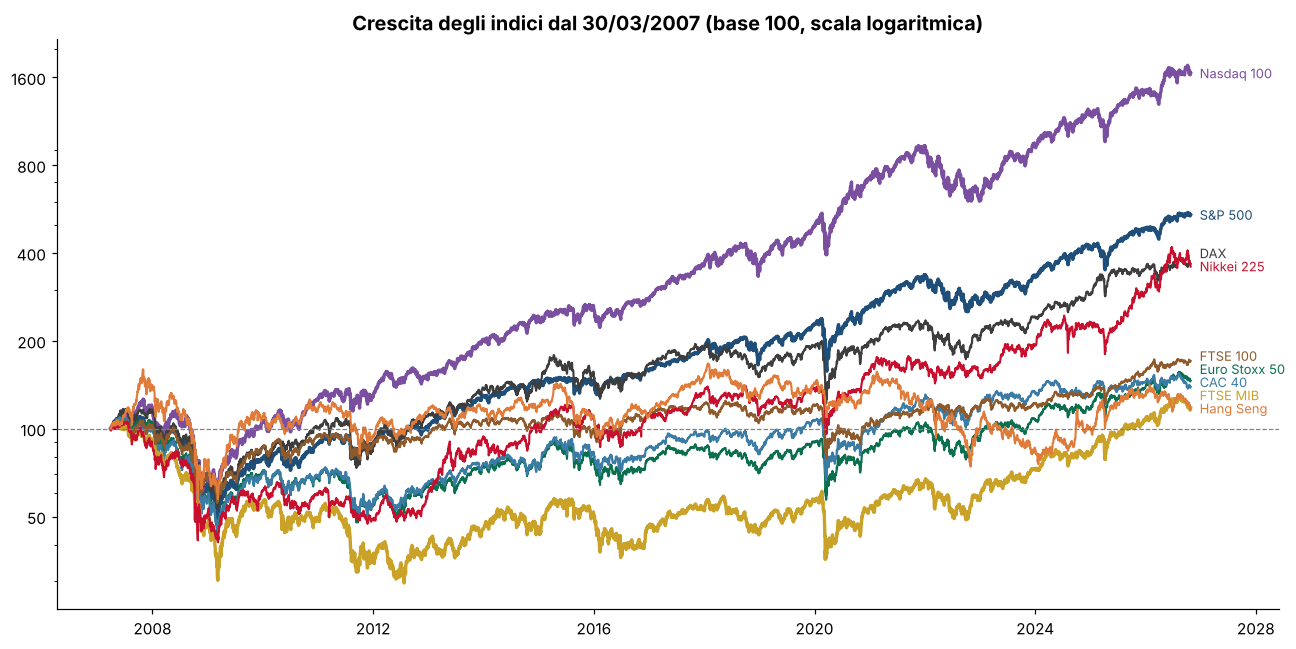

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))
p = prezzi.dropna(subset=["base100"])
fine_val = {}
for c in ORDINE:
    g = p[p.codice == c]
    ax.plot(g.data, g.base100, color=COLORE[c], lw=1.4 if c not in ("NASDAQ100", "SP500", "FTSEMIB") else 2.2, label=NOME[c])
    fine_val[c] = np.log10(g.base100.iloc[-1])
# etichette a destra, distanziate per non sovrapporsi
pos, ultimo = {}, -9
for c, v in sorted(fine_val.items(), key=lambda x: x[1]):
    ultimo = max(v, ultimo + 0.045); pos[c] = ultimo
for c in ORDINE:
    ax.text(p.data.max() + pd.Timedelta(days=60), 10 ** pos[c], NOME[c], color=COLORE[c], fontsize=8.5, va="center")
ax.set_yscale("log"); ax.set_yticks([50, 100, 200, 400, 800, 1600]); ax.set_yticklabels([50, 100, 200, 400, 800, 1600])
ax.axhline(100, color="grey", lw=0.8, ls="--")
ax.set_title("Crescita degli indici dal 30/03/2007 (base 100, scala logaritmica)"); ax.set_xlim(right=pd.Timestamp("2028-06-01"))
salva("01_crescita_base100")

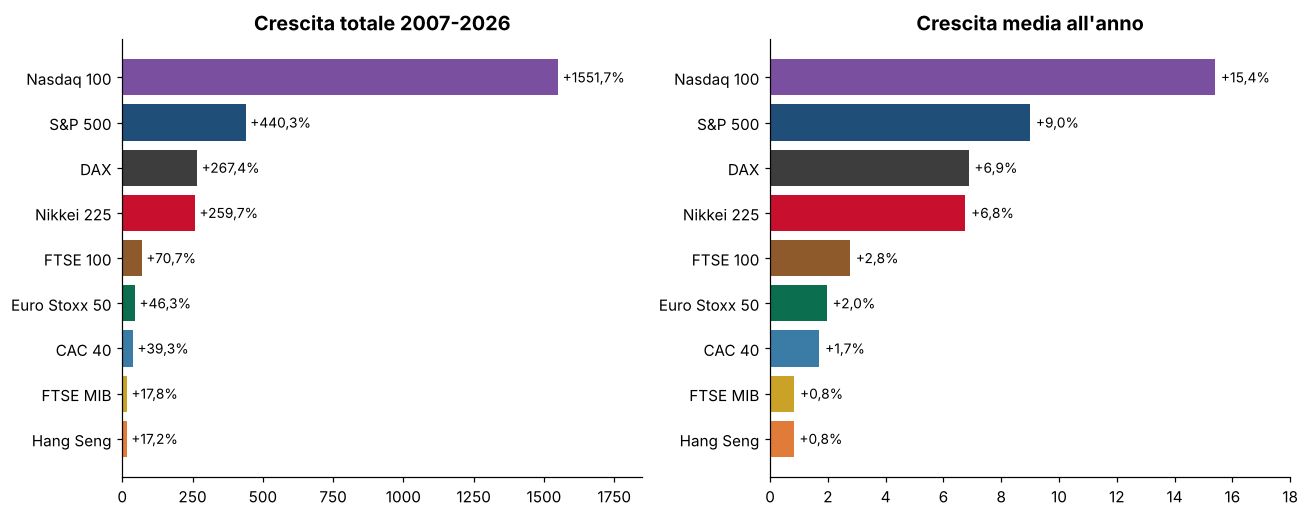

,posizione,nome,valore_inizio,valore_fine,crescita_pct,crescita_annua_pct
6,1,Nasdaq 100,1772.4,29273.4,1551.7,15.4
8,2,S&P 500,1420.9,7676.8,440.3,9.0
1,3,DAX,6917.0,25410.8,267.4,6.9
7,4,Nikkei 225,17287.6,62189.6,259.7,6.8
3,5,FTSE 100,6308.0,10767.3,70.7,2.8
2,6,Euro Stoxx 50,4181.0,6116.2,46.3,2.0
0,7,CAC 40,5634.2,7847.3,39.3,1.7
4,8,FTSE MIB,41771.0,49187.0,17.8,0.8
5,9,Hang Seng,19800.9,23211.8,17.2,0.8


In [3]:
o = riep.sort_values("crescita_pct")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].barh(o.nome, o.crescita_pct, color=o.colore)
for y, v in enumerate(o.crescita_pct): ax[0].text(v + 15, y, pct(v), va="center", fontsize=9)
ax[0].set_title("Crescita totale 2007-2026"); ax[0].set_xlim(0, 1850)
ax[1].barh(o.nome, o.crescita_annua_pct, color=o.colore)
for y, v in enumerate(o.crescita_annua_pct): ax[1].text(v + 0.2, y, pct(v), va="center", fontsize=9)
ax[1].set_title("Crescita media all'anno"); ax[1].set_xlim(0, 18)
salva("02_crescita_totale_annua")
riep.sort_values("posizione")[["posizione", "nome", "valore_inizio", "valore_fine", "crescita_pct", "crescita_annua_pct"]].round(1)

💡 **Cosa vediamo**

📌 Il **Nasdaq 100** (le grandi aziende tecnologiche americane) ha moltiplicato il valore per **16 volte**.

📌 Anche l'**S&P 500** è più che quintuplicato.

📌 Le Borse europee sono cresciute molto meno: il **FTSE MIB** italiano solo **+18%** in quasi 20 anni.

⚠️ **Attenzione ai dividendi**: quasi tutti questi indici contano solo i prezzi.
Il **DAX** tedesco invece aggiunge anche i dividendi: per questo sembra molto più forte delle altre Borse europee.

## 2️⃣ 💶 E se conto tutto in euro?

📌 Un italiano che compra un indice americano o giapponese deve prima cambiare gli euro in dollari o yen.

📌 Se poi il dollaro si rafforza, guadagna di più. Se lo yen si indebolisce, guadagna di meno.

,valuta,1 € valeva (2007),1 € vale oggi,valuta contro euro
0,GBP,0.679,0.838,"-19,1%"
1,HKD,10.433,8.797,"+18,6%"
2,JPY,157.360,175.917,"-10,5%"
3,USD,1.336,1.122,"+19,1%"


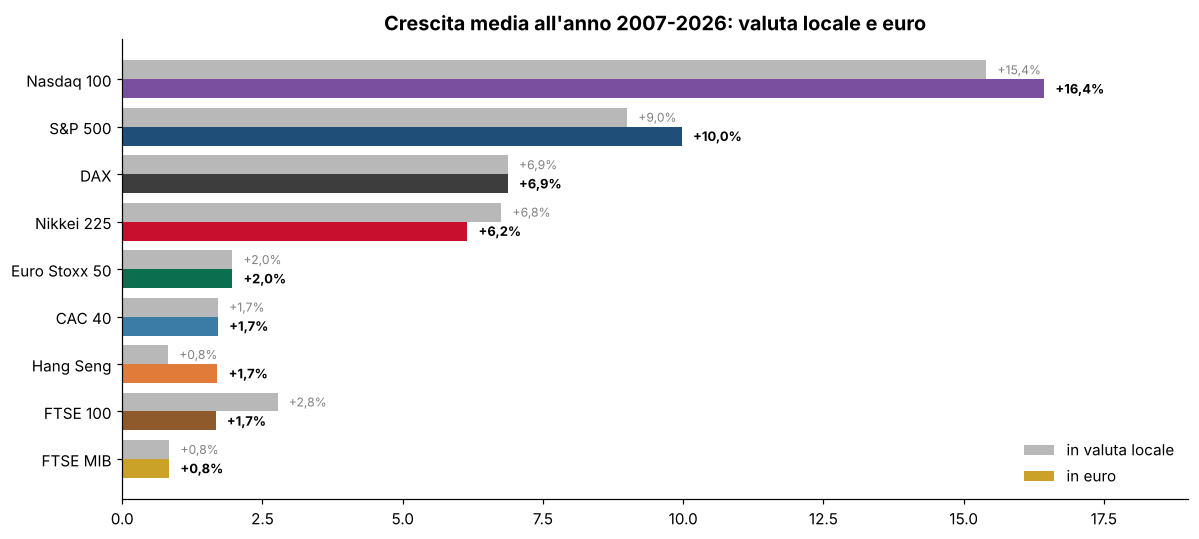

,posizione_eur,nome,valuta,crescita_pct,crescita_eur_pct
6,1,Nasdaq 100,USD,1551.7,1867.0
8,2,S&P 500,USD,440.3,543.4
1,3,DAX,EUR,267.4,267.4
7,4,Nikkei 225,JPY,259.7,221.8
2,5,Euro Stoxx 50,EUR,46.3,46.3
0,6,CAC 40,EUR,39.3,39.3
5,7,Hang Seng,HKD,17.2,39.0
3,8,FTSE 100,GBP,70.7,38.2
4,9,FTSE MIB,EUR,17.8,17.8


In [4]:
inizio, fine = pd.Timestamp("2007-03-30"), prezzi.data.max()
var = []
for v, g in cambi.groupby("valuta"):
    g = g.set_index("data").euro_vale
    a, b = g[:inizio].iloc[-1], g[:fine].iloc[-1]
    var.append({"valuta": v, "1 € valeva (2007)": round(a, 3), "1 € vale oggi": round(b, 3),
                "valuta contro euro": pct((a / b - 1) * 100)})
display(pd.DataFrame(var))

o = riep.sort_values("crescita_eur_pct")
y = np.arange(len(o))
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(y + 0.2, o.crescita_annua_pct, 0.4, color="#B8B8B8", label="in valuta locale")
ax.barh(y - 0.2, o.crescita_annua_eur_pct, 0.4, color=o.colore, label="in euro")
for i, (a, b) in enumerate(zip(o.crescita_annua_pct, o.crescita_annua_eur_pct)):
    ax.text(a + 0.2, i + 0.2, pct(a), va="center", fontsize=8, color="grey")
    ax.text(b + 0.2, i - 0.2, pct(b), va="center", fontsize=8.5, fontweight="bold")
ax.set_yticks(y, o.nome); ax.set_xlim(0, 19); ax.legend(frameon=False, loc="lower right")
ax.set_title("Crescita media all'anno 2007-2026: valuta locale e euro")
salva("03_crescita_in_euro")
riep.sort_values("posizione_eur")[["posizione_eur", "nome", "valuta", "crescita_pct", "crescita_eur_pct"]].round(1)

In [5]:
# esempio storico: quanto varrebbero oggi 10.000 € messi il 30/03/2007 (solo prezzi, senza costi né tasse)
es = riep[["nome", "crescita_eur_pct"]].assign(valore_oggi=lambda d: (10000 * (1 + d.crescita_eur_pct / 100)).round(-2))
es.sort_values("valore_oggi", ascending=False)

,nome,crescita_eur_pct,valore_oggi
6,Nasdaq 100,1866.959,196700.0
8,S&P 500,543.430,64300.0
1,DAX,267.366,36700.0
7,Nikkei 225,221.787,32200.0
2,Euro Stoxx 50,46.285,14600.0
0,CAC 40,39.281,13900.0
5,Hang Seng,39.026,13900.0
3,FTSE 100,38.164,13800.0
4,FTSE MIB,17.754,11800.0


💡 **Cosa vediamo**

📌 Il **dollaro** si è rafforzato contro l'euro: per un italiano gli indici americani sono andati **ancora meglio**.

📌 Lo **yen** si è indebolito: il Nikkei in euro rende meno che in yen.

📌 La **sterlina** si è indebolita: il FTSE 100 in euro scende da +71% a circa +38%.

📌 Le Borse dell'euro (DAX, CAC 40, Euro Stoxx 50, FTSE MIB) non cambiano: sono già in euro.

## 3️⃣ 🎢 Quale indice è più rischioso?

📌 **Volatilità**: quanto si muove l'indice ogni giorno (deviazione standard dei rendimenti giornalieri × √252).
Più è alta, più l'indice sale e scende.

📌 **Massima caduta** (drawdown): la perdita più grande dal punto più alto al punto più basso.

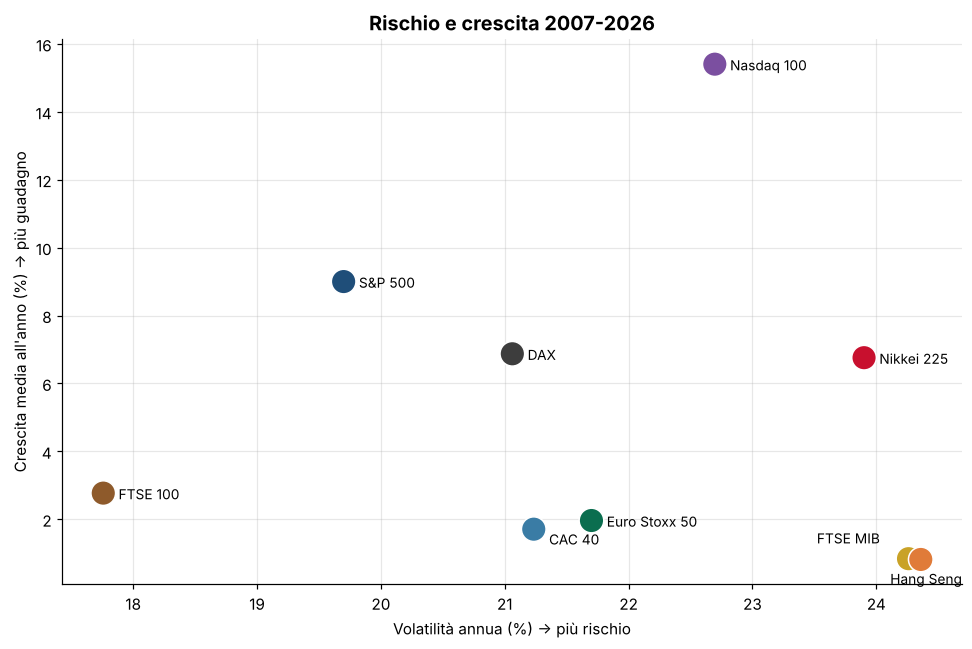

,nome,volatilita_annua_pct,max_caduta_pct,data_max_caduta,rischio_rendimento
3,FTSE 100,17.76,-47.83,2009-03-03,0.16
8,S&P 500,19.70,-56.78,2009-03-09,0.46
1,DAX,21.06,-54.77,2009-03-06,0.33
0,CAC 40,21.23,-59.16,2009-03-09,0.08
2,Euro Stoxx 50,21.70,-60.29,2009-03-09,0.09
6,Nasdaq 100,22.70,-53.71,2008-11-20,0.68
7,Nikkei 225,23.90,-61.37,2009-03-10,0.28
4,FTSE MIB,24.26,-72.13,2012-07-24,0.04
5,Hang Seng,24.36,-65.18,2008-10-27,0.03


In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(riep.volatilita_annua_pct, riep.crescita_annua_pct, s=260, c=riep.colore, edgecolor="white", zorder=3)
sposta = {"FTSEMIB": (-60, 10), "HANGSENG": (-20, -16), "CAC40": (10, -10)}
for _, r in riep.iterrows():
    ax.annotate(r.nome, (r.volatilita_annua_pct, r.crescita_annua_pct), xytext=sposta.get(r.codice, (10, -4)), textcoords="offset points", fontsize=9)
ax.set_xlabel("Volatilità annua (%) → più rischio"); ax.set_ylabel("Crescita media all'anno (%) → più guadagno")
ax.set_title("Rischio e crescita 2007-2026"); ax.grid(alpha=0.3)
salva("04_rischio_crescita")
riep.sort_values("volatilita_annua_pct")[["nome", "volatilita_annua_pct", "max_caduta_pct", "data_max_caduta", "rischio_rendimento"]].round(2)

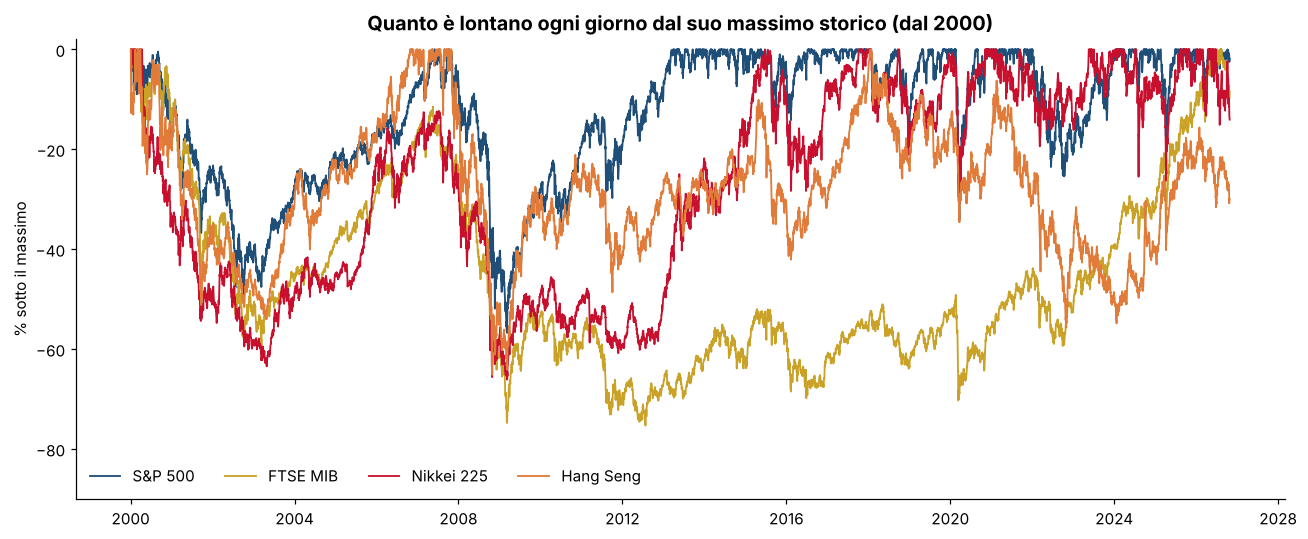

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for c in ["SP500", "FTSEMIB", "NIKKEI225", "HANGSENG"]:
    g = prezzi[prezzi.codice == c]
    ax.plot(g.data, g.drawdown_pct, color=COLORE[c], lw=1.2, label=NOME[c])
ax.set_title("Quanto è lontano ogni giorno dal suo massimo storico (dal 2000)"); ax.set_ylabel("% sotto il massimo")
ax.legend(frameon=False, ncol=4, loc="lower left"); ax.set_ylim(-90, 2)
salva("05_distanza_dal_massimo")

💡 **Cosa vediamo**

📌 Il **FTSE 100** è il più tranquillo, il **FTSE MIB** e l'**Hang Seng** i più agitati.

📌 Il **Nasdaq 100** è un po' più rischioso dell'S&P 500, ma ha guadagnato molto di più.

📌 Più rischio **non** vuol dire sempre più guadagno: FTSE MIB e Hang Seng hanno rischio alto e crescita bassa.

📌 Il FTSE MIB ha toccato **−72%** nel 2012, durante la crisi dei debiti europei.

## 4️⃣ 📉 Le crisi: quanto si perde e quanto si aspetta

📌 Per ogni crisi: dal **picco** (punto più alto prima della crisi) al **minimo**.

📌 **Recupero**: quando l'indice torna al valore del picco.

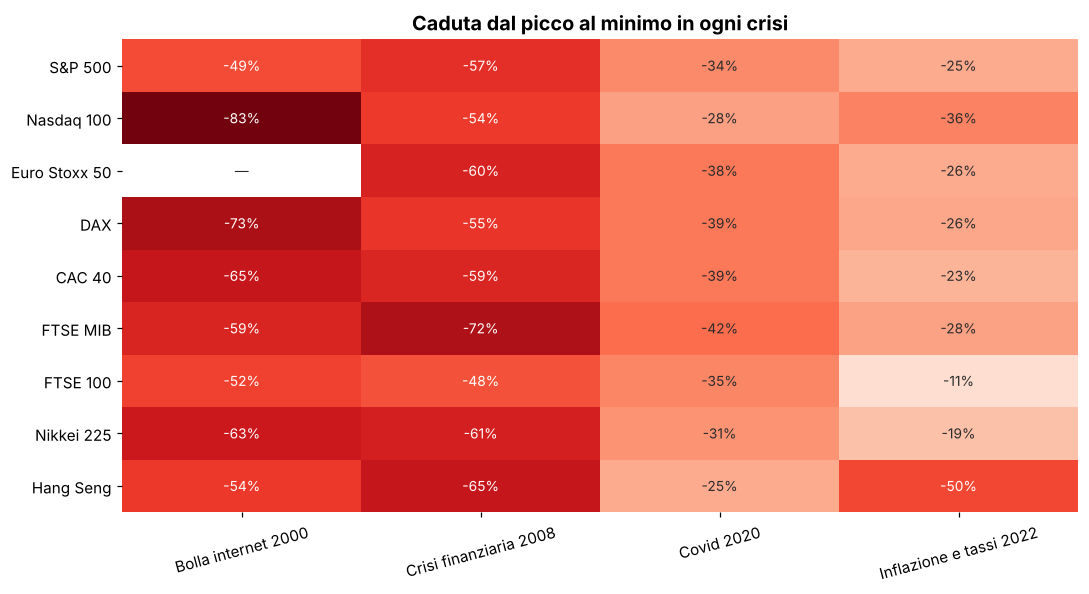

In [8]:
tab = crisi.pivot(index="nome", columns="crisi", values="caduta_pct")[sorted(crisi.crisi.unique(), key=lambda x: crisi[crisi.crisi == x].ordine_crisi.iloc[0])]
tab = tab.loc[[NOME[c] for c in ORDINE]]
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(tab.values, cmap="Reds_r", vmin=-85, vmax=0, aspect="auto")
ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=15); ax.set_yticks(range(tab.shape[0]), tab.index)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.0f}%", ha="center", va="center", color="white" if v < -45 else GRAFITE, fontsize=9)
ax.set_title("Caduta dal picco al minimo in ogni crisi"); ax.spines[:].set_visible(False)
salva("06_crisi_cadute")

In [9]:
rec = crisi.pivot(index="nome", columns="crisi", values="mesi_recupero")
rec = rec[sorted(crisi.crisi.unique(), key=lambda x: crisi[crisi.crisi == x].ordine_crisi.iloc[0])].loc[[NOME[c] for c in ORDINE]]
print("Mesi per tornare al picco (dal minimo). Vuoto = Euro Stoxx 50 non esisteva / Hang Seng non ancora tornato")
rec.round(0)

Mesi per tornare al picco (dal minimo). Vuoto = Euro Stoxx 50 non esisteva / Hang Seng non ancora tornato


crisi,Bolla internet 2000,Crisi finanziaria 2008,Covid 2020,Inflazione e tassi 2022
nome,,,,
S&P 500,56.0,49.0,5.0,15.0
Nasdaq 100,157.0,25.0,2.0,12.0
Euro Stoxx 50,NaN,178.0,12.0,7.0
DAX,51.0,50.0,9.0,8.0
CAC 40,224.0,145.0,13.0,6.0
FTSE MIB,278.0,200.0,15.0,9.0
FTSE 100,122.0,51.0,34.0,3.0
Nikkei 225,146.0,71.0,8.0,14.0
Hang Seng,42.0,111.0,10.0,NaN


💡 **Cosa vediamo**

📌 **2008** è stata la crisi più dura per tutti: cadute tra **−48%** e **−72%**.

📌 Il **Covid** ha fatto perdere molto in un mese, ma il recupero è stato veloce (l'S&P 500 in 5 mesi).

📌 Il **FTSE MIB** è tornato al picco del 2007 solo nel **novembre 2025**: oltre **16 anni** dopo il minimo.

📌 L'**Hang Seng** non ha ancora recuperato il picco del 2021.

📌 Nasdaq 100 dopo il 2000: oltre **13 anni** per recuperare: anche gli indici più forti possono restare giù a lungo.

## 5️⃣ 📅 Anno per anno

📌 Il rendimento di ogni anno, dal 2008 al 2025 (anni completi).

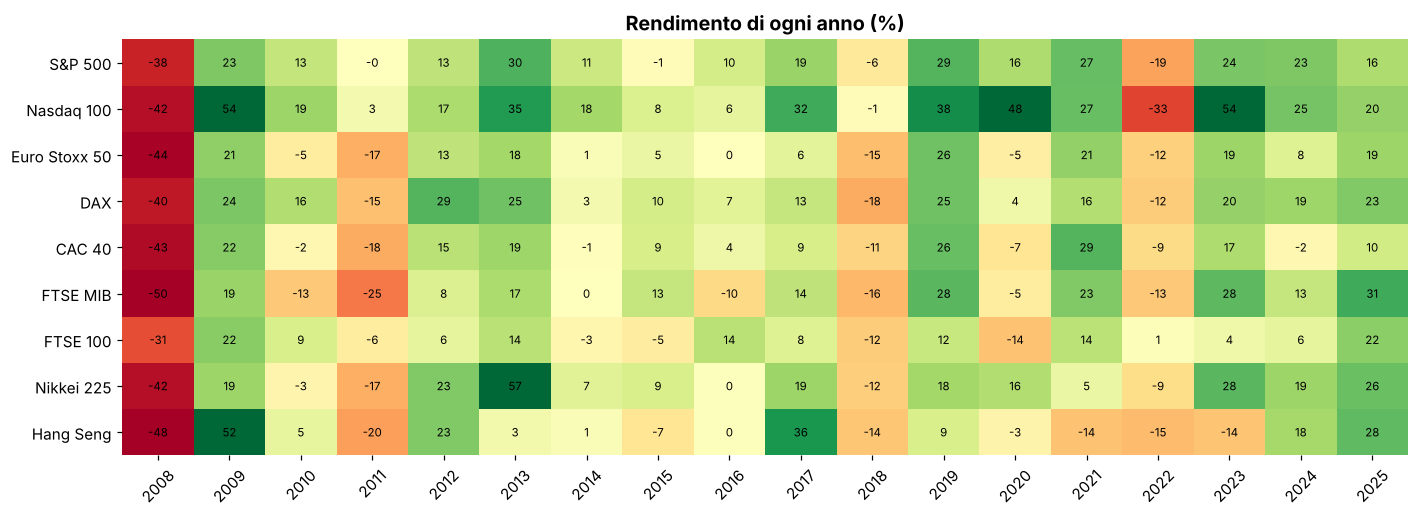

,nome,anni_positivi,anni_totali,anno_migliore,rend_anno_migliore_pct,anno_peggiore,rend_anno_peggiore_pct
0,CAC 40,10,18,2021,28.9,2008,-42.7
1,DAX,14,18,2012,29.1,2008,-40.4
2,Euro Stoxx 50,12,18,2019,25.5,2008,-44.3
3,FTSE 100,12,18,2009,22.1,2008,-31.3
4,FTSE MIB,11,18,2025,31.5,2008,-49.5
5,Hang Seng,10,18,2009,52.0,2008,-48.3
6,Nasdaq 100,15,18,2023,53.8,2008,-41.9
7,Nikkei 225,13,18,2013,56.7,2008,-42.1
8,S&P 500,13,18,2013,29.6,2008,-38.5


In [10]:
h = annui[(annui.anno >= 2008) & (annui.anno <= 2025)].pivot(index="codice", columns="anno", values="rend_pct").loc[ORDINE]
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.imshow(h.values, cmap="RdYlGn", vmin=-45, vmax=45, aspect="auto")
ax.set_xticks(range(h.shape[1]), h.columns, rotation=45); ax.set_yticks(range(h.shape[0]), [NOME[c] for c in h.index])
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        ax.text(j, i, f"{h.values[i, j]:.0f}", ha="center", va="center", fontsize=7.5)
ax.set_title("Rendimento di ogni anno (%)"); ax.spines[:].set_visible(False)
salva("07_rendimenti_anno")
riep[["nome", "anni_positivi", "anni_totali", "anno_migliore", "rend_anno_migliore_pct", "anno_peggiore", "rend_anno_peggiore_pct"]].round(1)

💡 **Cosa vediamo**

📌 Il **2008** e il **2018** sono rossi per tutti. Il **2022** quasi ovunque (solo il FTSE 100 chiude a +1%).

📌 Il **Nasdaq 100** è stato positivo in **15 anni su 18**, il CAC 40 e l'Hang Seng solo in 10.

📌 Dopo un anno molto negativo spesso arriva un anno molto positivo (2009, 2019, 2023).

## 6️⃣ 🔗 Le Borse si muovono insieme?

📌 **Correlazione** dei rendimenti mensili (aprile 2007 – settembre 2026).

📌 1 = si muovono sempre insieme · 0 = nessun legame.

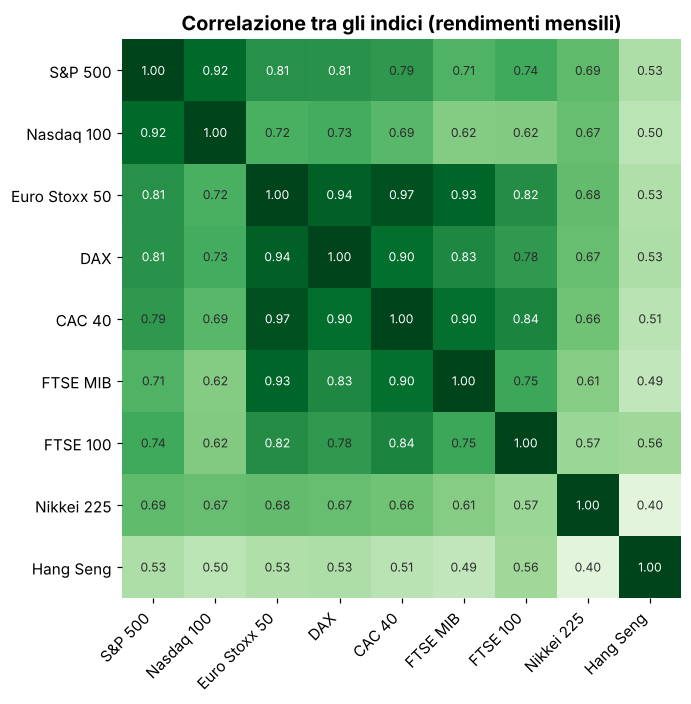

Le coppie più legate:


,codice_a,codice_b,correlazione
22,EUROSTOXX50,FTSEMIB,0.927
11,DAX,EUROSTOXX50,0.939
2,CAC40,EUROSTOXX50,0.971


Le coppie meno legate:


,codice_a,codice_b,correlazione
52,HANGSENG,NIKKEI225,0.395
41,FTSEMIB,HANGSENG,0.488
51,HANGSENG,NASDAQ100,0.501


In [11]:
m = corr.pivot(index="codice_a", columns="codice_b", values="correlazione").loc[ORDINE, ORDINE]
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(m.values, cmap="Greens", vmin=0.3, vmax=1)
nomi = [NOME[c] for c in ORDINE]
ax.set_xticks(range(9), nomi, rotation=45, ha="right"); ax.set_yticks(range(9), nomi)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if m.values[i, j] > 0.8 else GRAFITE)
ax.set_title("Correlazione tra gli indici (rendimenti mensili)"); ax.spines[:].set_visible(False)
salva("08_correlazioni")
c2 = corr[corr.codice_a < corr.codice_b].sort_values("correlazione")
print("Le coppie più legate:"); display(c2.tail(3)); print("Le coppie meno legate:"); display(c2.head(3))

💡 **Cosa vediamo**

📌 Le Borse **europee** si muovono quasi insieme (CAC 40 ed Euro Stoxx 50: **0,97**).

📌 Anche **S&P 500** e **Nasdaq 100** sono molto legati (**0,92**).

📌 L'**Hang Seng** e il **Nikkei** sono i più "diversi": dipendono di più dall'economia asiatica.

📌 Nelle grandi crisi però tutte le Borse scendono insieme.

## ✅ Conclusioni

1️⃣ 🏆 Dal 2007 ha vinto l'**America**: Nasdaq 100 **+1.552%**, S&P 500 **+440%**. In Europa solo il DAX (con i dividendi) tiene il passo.

2️⃣ 💶 In **euro** gli indici americani vanno ancora meglio (dollaro più forte), Nikkei e FTSE 100 un po' peggio.

3️⃣ 🎢 Il più tranquillo è il **FTSE 100**. I più agitati sono **FTSE MIB** e **Hang Seng**, che sono anche cresciuti poco.

4️⃣ 📉 Il **2008** è stata la crisi peggiore. Il FTSE MIB ci ha messo oltre **16 anni** a tornare al picco del 2007.

5️⃣ 🔗 Le Borse europee si muovono quasi insieme. Asia e America danno più varietà.

⚠️ Solo analisi storica dei prezzi: niente dividendi (tranne DAX), costi o tasse. Il passato non dice nulla sul futuro.